## **Thông tin bắt buộc**

MSSV:24738801

HoTen:Phan Chi Thanh

SoMay: 37



**số máy chỉ điền 2 con số, vd: 02**

## **Coding 10đ**

* import thư viện

In [48]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt

### **Discovery & Structuring (1.9đ)**


* đọc file csv, in 3 dòng cuối tiên (0.2đ)


In [49]:
df = pd.read_csv("posting2.csv", low_memory=False)
df.tail(3)

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
4997,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
4998,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
4999,35982263,NaN,Service Technician (duplicate job_id),Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0


* đọc thông tin data (0.15đ)

In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 31 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   job_id                      5000 non-null   int64  
 1   company_name                4931 non-null   str    
 2   title                       5000 non-null   str    
 3   description                 5000 non-null   str    
 4   max_salary                  1196 non-null   float64
 5   pay_period                  1442 non-null   str    
 6   location                    5000 non-null   str    
 7   company_id                  4931 non-null   float64
 8   views                       4943 non-null   float64
 9   med_salary                  246 non-null    float64
 10  min_salary                  1196 non-null   float64
 11  formatted_work_type         5000 non-null   str    
 12  applies                     947 non-null    float64
 13  original_listed_time        5000 non-null   

* in thông tin số dòng và số cột (0.15đ)

In [51]:
print("so dong la", df.shape[0])
print("so cot la", df.shape[1])

so dong la 5000
so cot la 31


* in ra các giá trị formatted_work_type trong bộ data (0.15đ)

In [52]:
df['formatted_work_type']

0       Full-time
1       Full-time
2       Full-time
3       Full-time
4       Full-time
          ...    
4995    Full-time
4996    Full-time
4997    Full-time
4998    Full-time
4999    Full-time
Name: formatted_work_type, Length: 5000, dtype: str

* đổi tên cột normalized_salary --> salary và formatted_experience_level --> experience_level (0.2đ)

In [53]:
df.rename(columns= {
     'normalized_salary': 'salary' ,
       'formatted_experience_level': 'experience_level'
}, inplace=True)

* in lại danh sách các cột sau khi rename (0.15đ)

In [54]:
df.columns.tolist()

['job_id',
 'company_name',
 'title',
 'description',
 'max_salary',
 'pay_period',
 'location',
 'company_id',
 'views',
 'med_salary',
 'min_salary',
 'formatted_work_type',
 'applies',
 'original_listed_time',
 'remote_allowed',
 'job_posting_url',
 'application_url',
 'application_type',
 'expiry',
 'closed_time',
 'experience_level',
 'skills_desc',
 'listed_time',
 'posting_domain',
 'sponsored',
 'work_type',
 'currency',
 'compensation_type',
 'salary',
 'zip_code',
 'fips']

* Tạo dataframe df_profile bao gồm dtype, nunique, missing_count, missing_percentage. Sắp xếp giảm dần theo missing_percentage. (0.5đ)


In [55]:
type =  df.dtypes
nun = df.nunique()
misscout = df.isnull().sum()
missper =(df.isnull().sum() / len(df) )* 100
df_profile = pd.DataFrame({
    'dtype': type,
    'nunique' : nun,
    'missing_count':misscout,
    'missing_percentage': missper
})
df_profile

,dtype,nunique,missing_count,missing_percentage
job_id,int64,4995,0,0.00
company_name,str,2858,69,1.38
title,str,4281,0,0.00
description,str,4825,0,0.00
max_salary,float64,532,3804,76.08
pay_period,str,4,3558,71.16
location,str,1741,0,0.00
company_id,float64,2860,69,1.38
views,float64,182,57,1.14
med_salary,float64,147,4754,95.08


* tìm số dòng thỏa điều kiện formatted_work_type là Full-time và salary từ 100000 trở lên (0.2đ)

In [56]:
df[(df['formatted_work_type'] =='Full-time') & (df['salary'] > 100000)]

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,salary,zip_code,fips
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
14,3619548798,"Dexterity, Inc.",Senior Mechanical Engineer,Senior Mechanical Engineer\nLocation: Redwood ...,190000.0,YEARLY,"Redwood City, CA",28173564.0,3.0,NaN,...,NaN,1.712885e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,170000.0,94061.0,6081.0
58,3884433957,Vaco,HRIS Analyst,***HRIS Analyst***\n***Remote Position***\n***...,NaN,HOURLY,"Atlanta, GA",11229.0,34.0,57.0,...,NaN,1.712349e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,118560.0,30303.0,13121.0
60,3884434376,Tandym Group,General Dermatologist,A health services organization in Ohio is curr...,575000.0,YEARLY,"Akron, OH",86041588.0,5.0,NaN,...,NaN,1.712348e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,557500.0,44301.0,39153.0
64,3884435101,Ledgent Technology,Sr. .NET Developer (BOCA RATON),Ledgent Technology is actively seeking a seaso...,140000.0,YEARLY,"Boca Raton, FL",10592585.0,26.0,NaN,...,NaN,1.712346e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,125000.0,33428.0,12099.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4952,3906256394,Circle,Senior Enablement Lead,Circle is a financial technology company at th...,120000.0,YEARLY,"Boston, MA",3509899.0,3.0,NaN,...,NaN,1.713568e+12,boards.greenhouse.io,0,FULL_TIME,USD,BASE_SALARY,105000.0,2108.0,25025.0
4965,3906258119,TD,Sr Audit Group Manager Retail Distribution,Work Location:\n\nMt Laurel - Operations Cente...,183460.0,YEARLY,"Laurel, MT",2775.0,5.0,NaN,...,NaN,1.713568e+12,td.wd3.myworkdayjobs.com,0,FULL_TIME,USD,BASE_SALARY,148180.0,59044.0,30111.0
4987,3906260144,Sterling Engineering,Operations Manager,Overview/Summary:Join a dynamic and innovative...,135000.0,YEARLY,Kansas City Metropolitan Area,24211.0,NaN,NaN,...,NaN,1.713567e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,127500.0,NaN,NaN
4989,3906261027,Cisco,Solutions Engineer,"Why you'll love Cisco\n\nWe change the World, ...",236800.0,YEARLY,"Herndon, VA",1063.0,4.0,NaN,...,NaN,1.713568e+12,jobs.cisco.com,0,FULL_TIME,USD,BASE_SALARY,210850.0,20170.0,NaN


* cho biết số dòng có remote_allowed bằng 1 và application_type là OffsiteApply (0.2đ)

In [57]:
teo = df[(df['remote_allowed'] == 1) & (df['application_type'] == 'OffsiteApply')]
print('so dong ', teo.shape[0])

so dong  306


### **Cleaning**

#### **Duplicated & missing data (3.05đ)**


Duplicate count (0.4đ)
* In số dòng trùng cả bản ghi.
* In số job_id bị lặp.


In [14]:

print("so dong trung ", df.duplicated().shape[0])
print("so job bi lap ", df['job_id'].duplicated().shape[0])

so dong trung  5000
so job bi lap  5000


* xoá số dòng duplicated cả bản ghi (0.25đ)


In [15]:
df = df.drop_duplicates(df)
df.shape

(4997, 31)

* xoá số dòng duplicated số job_id (0.25đ)


In [16]:

df = df.drop_duplicates(subset=["job_id"])
df.shape

# df[dsa l] = df .isna. f kieu int 

(4995, 31)

df2 missing table (0.4đ)
* Kiểm tra dữ liệu có missing không?
* Nếu có, tạo df2 gồm 3 cột: column_name, missing_count, missing_percentage
* Sắp xếp df2 giảm dần theo missing_count
* Chỉ giữ các dòng có missing_count khác 0

In [20]:
# df2 =?
df = df.copy()
misscout = df.isnull().sum()
missper =(df.isnull().mean())* 100
df2 = pd.DataFrame ({'columns_name' : df.columns,
                     'missing_count': misscout,
                     "missing_percent": missper} )

df2 


,columns_name,missing_count,missing_percent
job_id,job_id,0,0.000000
company_name,company_name,67,1.341341
title,title,0,0.000000
description,description,0,0.000000
max_salary,max_salary,3804,76.156156
pay_period,pay_period,3558,71.231231
location,location,0,0.000000
company_id,company_id,67,1.341341
views,views,57,1.141141
med_salary,med_salary,4749,95.075075


Missing-value bar chart (0.4đ)
* Sử dụng barchart để vẽ df2 với x là missing_count, y là column_name. Trong đó xlabel là số lượng thiếu, ylabel là tên cột

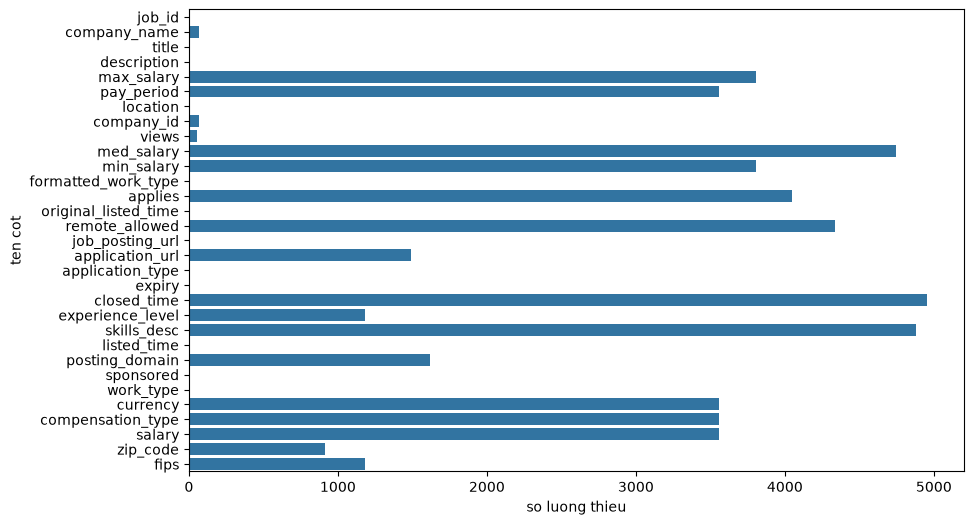

In [18]:
import matplotlib.pyplot as plt
plt.figure( figsize = (10, 6))
sns.barplot(
    x = misscout,
    y = df.columns
)
plt.xlabel('so luong thieu')
plt.ylabel("ten cot")
plt.show()

* tạo ra 1 cột salary_missing, nếu salary bị thiếu thì bằng 1, ngược lại bằng 0, gợi ý isna() (0.25đ)


In [21]:
df['salary_missing'] =df['salary'].isna().astype(int)

* salary_missing_by_work = Nhóm theo formatted_work_type, tính mean của cột salary_missing rồi nhân 100 để ra tỷ lệ thiếu (%). Sắp xếp tăng dần và đổi tên thành salary_missing_pct. (0.25đ)


In [23]:
df.columns

Index(['job_id', 'company_name', 'title', 'description', 'max_salary',
       'pay_period', 'location', 'company_id', 'views', 'med_salary',
       'min_salary', 'formatted_work_type', 'applies', 'original_listed_time',
       'remote_allowed', 'job_posting_url', 'application_url',
       'application_type', 'expiry', 'closed_time', 'experience_level',
       'skills_desc', 'listed_time', 'posting_domain', 'sponsored',
       'work_type', 'currency', 'compensation_type', 'salary', 'zip_code',
       'fips', 'salary_missing'],
      dtype='str')

In [24]:
# salary_missing_by_work =?
salary_missing_by_work  = df.groupby('formatted_work_type')['salary_missing'].mean()*100
salary_missing_by_work = salary_missing_by_work.sort_values().rename('salary_missing_pct')

* Vẽ bar chart tỷ lệ thiếu salary theo formatted_work_type. xlabel là tỷ lệ thiếu (%), ylabel là tên nhóm. (0.25đ)


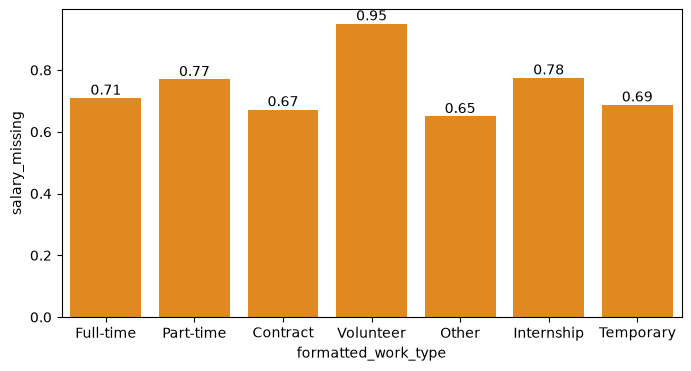

In [ ]:
plt.figure(figsize=(8, 4))

ax = sns.barplot(
    data=df,
    x='formatted_work_type',
    y='salary_missing',
    color="darkorange",
    errorbar=None  
)

ax.bar_label(ax.containers[0], fmt='%.2f')
plt.show()

Fill with mode/mean/median (0.6đ)
* company_name: điền mode.
* views và applies: điền median.
* experience_level: ô trống điền nhãn Unknown.
* Tạo remote_flag từ remote_allowed, ô trống điền 0.
* salary: không điền.


In [33]:
df['company_name'] = df['company_name'].fillna(df['company_name'].mode().iloc[0])
df['views'] = df['views'].fillna(df['views'].median())
df['applies'] = df['applies'].fillna(df['applies'].median())
df  =               df.fillna(value = {'experience_level':'Unknown'})
df = df.fillna(value = {'remote_allowed': '0'})
df['remote_flag']  = df['remote_allowed']
df= df.dropna(subset = ['salary'])


In [34]:
# kiểm tra lại sau xử lý missing data
df[["company_name", "views", "applies", "experience_level", "salary"]].isnull().sum()

company_name        0
views               0
applies             0
experience_level    0
salary              0
dtype: int64

#### **Outlier (2.5đ)**

* df2_1 chỉ chứa views và salary. Hiển thị 2 dòng (0.2đ)


In [36]:
df2_1 = df[['views','salary']]
df2_1.head(2)


,views,salary
0,20.0,38480.0
1,1.0,83200.0


df3 with concat (0.5đ)
* Tạo dataframe df3 bằng CONCAT
* df3 gồm các cột Q1, Q3, IQR, lower_bound, upper_bound, outlier_count
* Trong đó cột Q1 là 22%, Q3 = 78%

In [37]:
# df3 = ?

df = df.select_dtypes('number')
q1 = df.quantile(0.22)
q3 = df.quantile(0.78)
iqr = q3 - q1
lowerr = q1 - 1.5 * iqr
upperr = q3 +1.5 * iqr
oulierr = ((df> upperr) | (df < lowerr)).sum()
df3 = pd.concat([q1, q3, iqr, lowerr, upperr, oulierr], axis=1)
df3.columns = ["Q1", "Q3", "IQR", "lower_bound", "upper_bound", "oulier_count"]
df3


,Q1,Q3,IQR,lower_bound,upper_bound,oulier_count
job_id,3.891095e+09,3.904723e+09,1.362748e+07,3.870654e+09,3.925164e+09,15
max_salary,4.461600e+01,1.500000e+05,1.499554e+05,-2.248885e+05,3.749331e+05,12
company_id,1.122900e+04,9.952501e+06,9.941272e+06,-1.490068e+07,2.486441e+07,188
views,3.000000e+00,1.200000e+01,9.000000e+00,-1.050000e+01,2.550000e+01,185
med_salary,1.800000e+01,3.711270e+04,3.709470e+04,-5.562406e+04,9.275476e+04,19
min_salary,3.298000e+01,1.100000e+05,1.099670e+05,-1.649175e+05,2.749505e+05,7
applies,3.000000e+00,3.000000e+00,0.000000e+00,3.000000e+00,3.000000e+00,325
original_listed_time,1.712858e+12,1.713485e+12,6.270686e+08,1.711917e+12,1.714425e+12,21
expiry,1.715458e+12,1.716110e+12,6.520050e+08,1.714480e+12,1.717088e+12,72
closed_time,1.712636e+12,1.713305e+12,6.688127e+08,1.711633e+12,1.714308e+12,0


df4 outlier filter (0.4đ)
* df4 lọc lại dữ liệu, loại các dòng có ít nhất một cột số trong df2_1 nằm ngoài [lower_bound, upper_bound]

In [47]:
# df4 =?
df4  = df.copy()
df4 = df[((df2_1 >= lowerr) & (df2_1 <= upperr)).any(axis = 1)]

ValueError: Operands are not aligned. Do `left, right = left.align(right, axis=1)` before operating.

In [40]:
df4.shape


(0, 16)

df5 clip (0.3đ)
* Tạo df5 từ df bằng clip kéo ngưỡng về chặn trên chặn dưới

In [41]:
df5 = df.copy()
df5=df5.clip(upper= upperr, lower= lowerr, axis=1)

In [42]:
df5.shape


(1437, 16)

Histogram of salary (0.25đ)
* vẽ histogram cho cột salary trong df4
* title là "phân phối salary"
* xlabel là "salary (USD/year)"

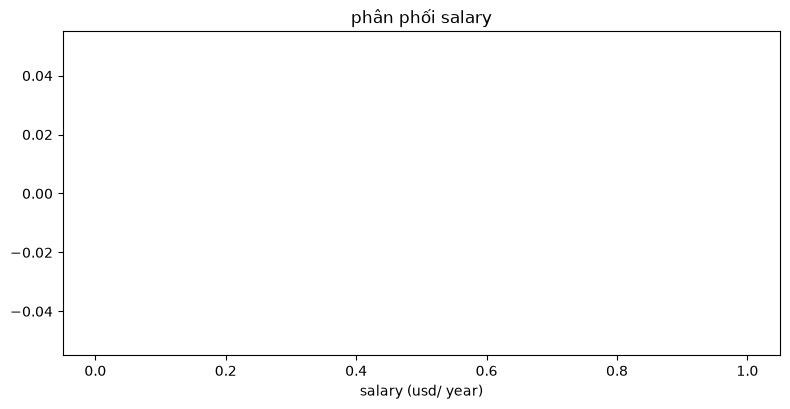

In [43]:
plt.figure(figsize=(8, 4))
plt.hist(df4['salary'].dropna(), bins=40, color="steelblue", edgecolor="white")
plt.title("phân phối salary")

plt.tight_layout()
plt.xlabel("salary (usd/ year)")
plt.show()

Is salary skewed? Print skew, kurtosis, mean, median (0.6đ)
* Dùng cột salary của df4 (bỏ giá trị thiếu). Dữ liệu có lệch không? In ra skew, kurtosis, mean, median.
* Từ kurtosis, so với phân phối chuẩn thì đỉnh nhọn hơn hay hai đuôi dày hơn?

In [ ]:
sala = df4['salary']
print("skew", sala.skew())
print("kurtosis", sala.kurtosis())
print("mean", sala.mean())
print("median", sala.median())
# du lieu lech phai, duoi ve phia gia tri lon va phan phoi dinh nhon hon

skew 35.45718979140207
kurtosis 1296.3292308318435
mean 557609.5553723034
median 83200.0


Gợi ý trả lời (tự điền theo số vừa in, không chép kết luận):

1. Xem dấu của skew. skew > 0 thì lệch phải, đuôi về phía giá trị lớn; skew < 0 thì lệch trái. Đối chiếu mean với median: bên nào lớn hơn thì đuôi kéo về bên đó.

2. kurtosis của pandas là excess kurtosis. Phân phối chuẩn có excess kurtosis bằng 0. Số vừa in > 0 thì đỉnh nhọn hơn và hai đuôi dày hơn chuẩn; < 0 thì đỉnh phẳng hơn và hai đuôi mỏng hơn chuẩn.

Create salary_log with np.log (0.25đ)

* Tạo cột salary_log trong df4 bằng np.log.
* salary không dương thì salary_log để NaN.
* Gợi ý: tạo cột salary_log toàn NaN trước. Dùng .loc với điều kiện salary > 0 rồi mới gán np.log. np.log chỉ nhận số dương.


In [193]:
salary_log  = df4['salary']
df4 = np.log(salary_log.where(salary_log < 0))

### **Univariate Analysis (0.55đ)**


* thống kê mô tả cho 2 cột salary và salary_log trong df4 (0.3đ)

In [ ]:
df['salary'].describe()

df['salary_log'].describe()

count    1.437000e+03
mean     5.576096e+05
std      1.450234e+07
min      0.000000e+00
25%      5.200000e+04
50%      8.320000e+04
75%      1.295000e+05
max      5.356000e+08
Name: salary, dtype: float64

* In skew, kurtosis, mean, median của salary_log. Vẽ hai histogram cạnh nhau: salary và salary_log. (0.25đ)


In [ ]:
print("salary_log skew:", ?)
print("salary_log kurtosis:", ?)
print("salary_log mean:",  ?)
print("salary_log median:",  ?)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df4["salary"].dropna(), bins=?, color=?, edgecolor=?)
axes[0].set_title("phân phối salary")
axes[0].set_xlabel("salary (USD/year)")

# salary_log tương tự salary
# axes[1].

for ax in axes:
    ax.set_ylabel("Số tin")
    
plt.tight_layout()
plt.show()

### **Bivariate & Multivariate Analysis (1.65đ)**

Xem mối quan hệ giữa các biến.

* Heatmap (0.3đ): Correlation heatmap giữa các cột số, bao gồm views, applies, min_salary, max_salary, med_salary, salary.

* df4 group by theo formatted_work_type, tính count, mean, median của salary (0.3đ), gợi ý: .agg([count,...])


* df4 group by theo experience_level, tính count, mean, median của salary. (0.5đ)


* Tạo pivot median salary theo experience_level (hàng) và formatted_work_type (cột). Vẽ heatmap. (0.55đ). Gợi ý: dùng pivot_table, index là hàng, columns là cột, values, aggfunc gọi hàm. Sau đó vẽ heatmap


In [ ]:
# salary_pivot = ?

# plt.figure(?)
# sns.heatmap(salary_pivot, annot=True, fmt=".0f", cmap="YlGnBu")
# plt.title("")
# plt.xlabel("")
# plt.ylabel("")
# plt.tight_layout()
# plt.show()

### **Publishing (0.35đ)**

* Lưu df4 ra file Excel, đặt tên df4.xlsx (0.2đ)

Không ghi các cột description, skills_desc, job_posting_url, application_url.


In [201]:
df4.to_csv("df4.xlsx")

* Sau đó lưu df4 ra file HTML, đặt tên df4.html (0.15đ)

Không ghi các cột description, skills_desc, job_posting_url, application_url.


In [202]:
df4.to_csv("df4.html")